# Wine Reviews EDA

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BLUE = "#2a78d6"
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
})

## Load

In [2]:
raw = pd.read_parquet("data_clean/winemag-data-130k-v2.parquet")
df = pd.read_parquet("data_clean/wine_reviews_clean.parquet")
raw.shape, df.shape

((119988, 13), (119922, 16))

## Overview

In [3]:
df.head()

,country,description,designation,points,price,province,region_1,region_2,taster_name,title,variety,winery,vintage,log_price,price_missing,country_group
0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia,2013,NaN,True,Italy
1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos,2011,2.708050,False,Portugal
2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm,2013,2.639057,False,US
3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,NaN,Alexander Peartree,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling,St. Julian,2013,2.564949,False,US
4,US,"Much like the regular bottling from 2012, this...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,Pinot Noir,Sweet Cheeks,2012,4.174387,False,US


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119922 entries, 0 to 119921
Data columns (total 16 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   country        119863 non-null  str    
 1   description    119922 non-null  str    
 2   designation    85404 non-null   str    
 3   points         119922 non-null  int64  
 4   price          111535 non-null  float64
 5   province       119863 non-null  str    
 6   region_1       100366 non-null  str    
 7   region_2       46752 non-null   str    
 8   taster_name    95015 non-null   str    
 9   title          119922 non-null  str    
 10  variety        119921 non-null  str    
 11  winery         119922 non-null  str    
 12  vintage        115633 non-null  Int64  
 13  log_price      111535 non-null  float64
 14  price_missing  119922 non-null  bool   
 15  country_group  119863 non-null  str    
dtypes: Int64(1), bool(1), float64(2), int64(1), str(11)
memory usage: 57.2 MB


In [5]:
df.describe()

,points,price,vintage,log_price
count,119922.000000,111535.000000,115633.0,111535.000000
mean,88.442304,35.572009,2010.587064,3.316752
std,3.093007,40.530179,3.6846,0.659089
min,80.000000,4.000000,1934.0,1.386294
25%,86.000000,17.000000,2009.0,2.833213
50%,88.000000,25.000000,2011.0,3.218876
75%,91.000000,42.000000,2013.0,3.737670
max,100.000000,2500.000000,2017.0,7.824046


In [6]:
df.describe(include="str")

,country,description,designation,province,region_1,region_2,taster_name,title,variety,winery,country_group
count,119863,119922,85404,119863,100366,46752,95015,119922,119921,119922,119863
unique,43,119922,37967,425,1229,17,19,118774,707,16754,27
top,US,"Aromas include tropical fruit, broom, brimston...",Reserve,California,Napa Valley,Central Coast,Roger Voss,Gloria Ferrer NV Sonoma Brut Sparkling (Sonoma...,Pinot Noir,Wines & Winemakers,US
freq,50440,1,1870,33644,4172,10229,23556,9,12276,211,50440


## Missing values

In [7]:
missing = (raw.isna().mean() * 100).round(1).sort_values()
missing[missing > 0]

price                     7.0
region_1                 16.3
taster_name              20.8
taster_twitter_handle    24.5
designation              28.8
region_2                 61.0
dtype: float64

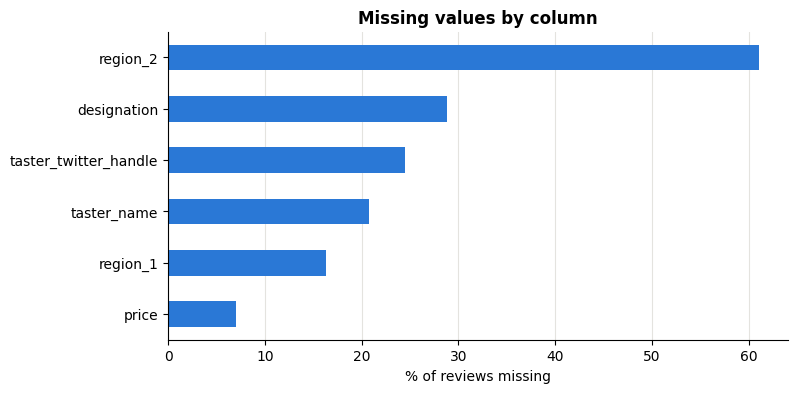

In [8]:
ax = missing[missing > 0].plot.barh(color=BLUE)
ax.set(title="Missing values by column", xlabel="% of reviews missing")
ax.grid(axis="y", visible=False)

In [9]:
raw.loc[raw["region_2"].notna(), "country"].value_counts()

country
US    46769
Name: count, dtype: int64

## Repeated reviews

In [10]:
raw.duplicated("description").sum()

np.int64(33)

In [11]:
repeats = raw[raw.duplicated("description", keep=False)].sort_values("description")
repeats[["title", "winery", "points", "price", "taster_name"]].head(6)

,title,winery,points,price,taster_name
68588,Château Pontac-Lynch 2012 Barrel Sample (Marg...,Château Pontac-Lynch,91,NaN,Roger Voss
68590,Château Maucaillou 2012 Barrel Sample (Moulis...,Château Maucaillou,91,NaN,Roger Voss
98989,Château Grand-Puy-Lacoste 2012 Barrel Sample ...,Château Grand-Puy-Lacoste,93,NaN,Roger Voss
98994,Château Gruaud Larose 2012 Barrel Sample (Sai...,Château Gruaud Larose,93,NaN,Roger Voss
70421,Stefano Accordini 2008 Passo Red (Rosso del Ve...,Stefano Accordini,88,35.0,NaN
70436,Stefano Accordini 2007 Passo Red (Rosso del Ve...,Stefano Accordini,88,35.0,NaN


In [12]:
repeats.groupby("description")["winery"].nunique().gt(1).sum()

np.int64(21)

## Taster Twitter handle

In [13]:
raw.groupby("taster_name")["taster_twitter_handle"].nunique().sort_values(ascending=False).head()

taster_name
Anne Krebiehl MW     1
Fiona Adams          1
Christina Pickard    1
Roger Voss           1
Michael Schachner    1
Name: taster_twitter_handle, dtype: int64

In [14]:
raw.loc[raw["taster_name"].isna(), "taster_twitter_handle"].notna().sum()

np.int64(0)

## Vintage extraction check

In [15]:
naive = raw["title"].str.extract(r"\b(19\d{2}|20[01]\d)\b")[0].astype("Int64")
raw.loc[naive < 1930, ["title", "winery"]].head()

,title,winery
7951,Guidi 1929 2012 Aurea Riserva (Vernaccia di S...,Guidi 1929
9688,1912 Winemakers 2011 Vinhas Velhas Branco Whit...,1912 Winemakers
37823,1912 Winemakers 2009 Piorro Reserva Red (Douro),1912 Winemakers
40107,1912 Winemakers 2013 Piorro Branco Colheita Wh...,1912 Winemakers
52997,1912 Winemakers 2009 Encosta do Bocho Grand Re...,1912 Winemakers


In [16]:
pd.Series([t.startswith(w) for t, w in zip(raw["title"], raw["winery"])]).all()

np.True_

In [17]:
df.loc[df["vintage"] < 1960, ["title", "vintage"]]

,title,vintage
40435,Kopke 1935 Colheita White (Port),1935
50387,"Bodegas Toro Albala, SL 1947 Don PX Reserva Es...",1947
74457,Kopke 1957 Colheita Tawny (Port),1957
78502,Messias 1952 Porto Envelhecido em Casco Colhei...,1952
82457,Burmester 1952 Colheita Tawny (Port),1952
85624,Kopke 1941 Colheita Tawny (Port),1941
100908,Adega Viuva Gomes 1934 Reserva Velho Red (Cola...,1934
109020,Gérard Bertrand 1945 Legend Vintage Red (Rives...,1945


## Points

In [18]:
df["points"].describe()

count    119922.000000
mean         88.442304
std           3.093007
min          80.000000
25%          86.000000
50%          88.000000
75%          91.000000
max         100.000000
Name: points, dtype: float64

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
        17, 18, 19, 20]),
 [Text(0, 0, '80'),
  Text(1, 0, '81'),
  Text(2, 0, '82'),
  Text(3, 0, '83'),
  Text(4, 0, '84'),
  Text(5, 0, '85'),
  Text(6, 0, '86'),
  Text(7, 0, '87'),
  Text(8, 0, '88'),
  Text(9, 0, '89'),
  Text(10, 0, '90'),
  Text(11, 0, '91'),
  Text(12, 0, '92'),
  Text(13, 0, '93'),
  Text(14, 0, '94'),
  Text(15, 0, '95'),
  Text(16, 0, '96'),
  Text(17, 0, '97'),
  Text(18, 0, '98'),
  Text(19, 0, '99'),
  Text(20, 0, '100')])

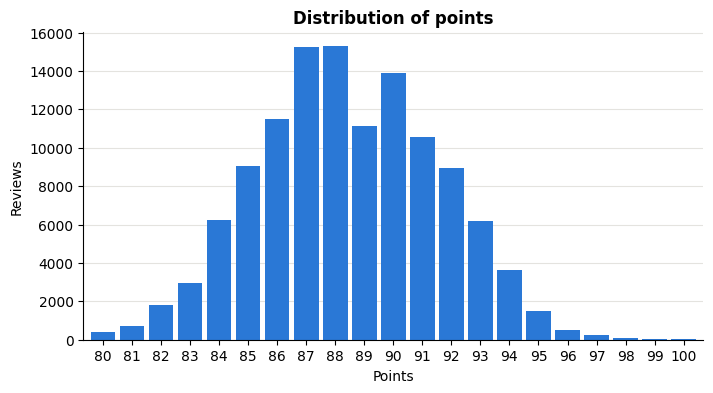

In [19]:
ax = df["points"].value_counts().sort_index().plot.bar(color=BLUE, width=0.85)
ax.set(title="Distribution of points", xlabel="Points", ylabel="Reviews")
ax.grid(axis="x", visible=False)
plt.xticks(rotation=0)

## Price

In [20]:
df["price"].describe()

count    111535.000000
mean         35.572009
std          40.530179
min           4.000000
25%          17.000000
50%          25.000000
75%          42.000000
max        2500.000000
Name: price, dtype: float64

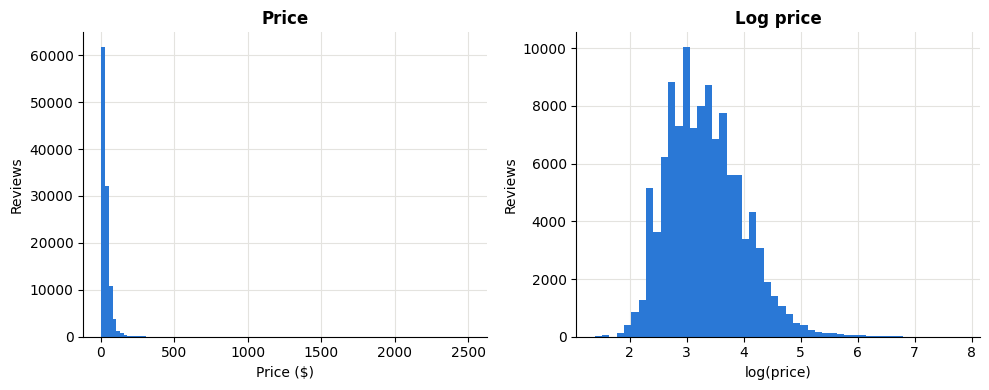

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
df["price"].plot.hist(bins=100, color=BLUE, ax=axes[0])
axes[0].set(title="Price", xlabel="Price ($)", ylabel="Reviews")
df["log_price"].plot.hist(bins=50, color=BLUE, ax=axes[1])
axes[1].set(title="Log price", xlabel="log(price)", ylabel="Reviews")
plt.tight_layout()

In [22]:
raw.loc[raw["price"] > 1000, ["title", "points", "price"]].sort_values("price", ascending=False)

,title,points,price
76317,Château les Ormes Sorbet 2013 Médoc,88,3300.0
15714,Château Pétrus 2014 Pomerol,96,2500.0
92592,Domaine du Comte Liger-Belair 2010 La Romanée,96,2500.0
111765,Blair 2013 Roger Rose Vineyard Chardonnay (Arr...,91,2013.0
105889,Domaine du Comte Liger-Belair 2005 La Romanée,96,2000.0
62713,Château Pétrus 2011 Pomerol,97,2000.0
1558,Château Margaux 2009 Margaux,98,1900.0
104354,Château Cheval Blanc 2010 Saint-Émilion,100,1500.0
104352,Château Lafite Rothschild 2010 Pauillac,100,1500.0
1575,Château Mouton Rothschild 2009 Pauillac,96,1300.0


In [23]:
df.groupby("country")["price"].apply(lambda s: s.isna().mean() * 100).round(1).sort_values(ascending=False).head(10)

country
Egypt           100.0
France           20.0
Austria          16.4
Portugal         14.3
Italy            13.6
Brazil           10.2
Slovenia          9.1
South Africa      8.1
England           6.3
New Zealand       3.0
Name: price, dtype: float64

## Points vs price

In [24]:
df[["points", "price"]].corr(method="spearman")

,points,price
points,1.000000,0.612571
price,0.612571,1.000000


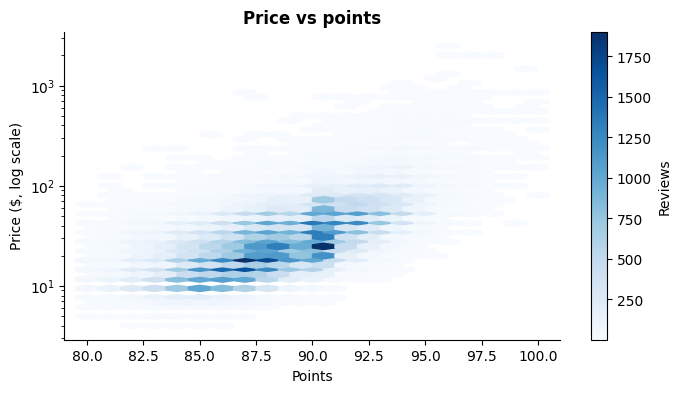

In [25]:
priced = df.dropna(subset=["price"])
fig, ax = plt.subplots()
hb = ax.hexbin(priced["points"], priced["price"], gridsize=(20, 30), yscale="log", cmap="Blues", mincnt=1)
fig.colorbar(hb, label="Reviews")
ax.set(title="Price vs points", xlabel="Points", ylabel="Price ($, log scale)")
ax.grid(False)

[Text(0.5, 1.0, 'Median price by points'),
 Text(0.5, 0, 'Points'),
 Text(0, 0.5, 'Median price ($)')]

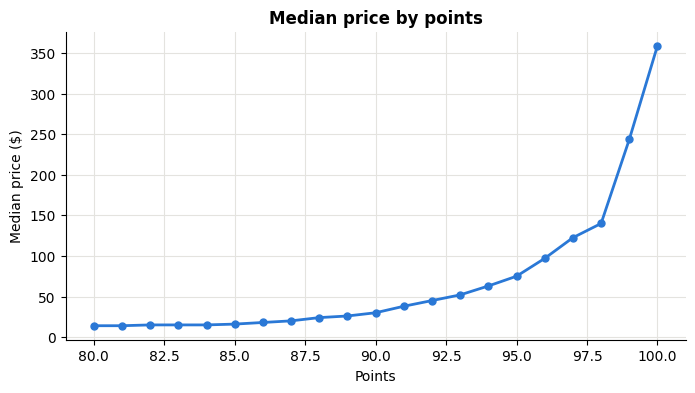

In [26]:
median_price = priced.groupby("points")["price"].median()
ax = median_price.plot(color=BLUE, linewidth=2, marker="o", markersize=5)
ax.set(title="Median price by points", xlabel="Points", ylabel="Median price ($)")

## Countries

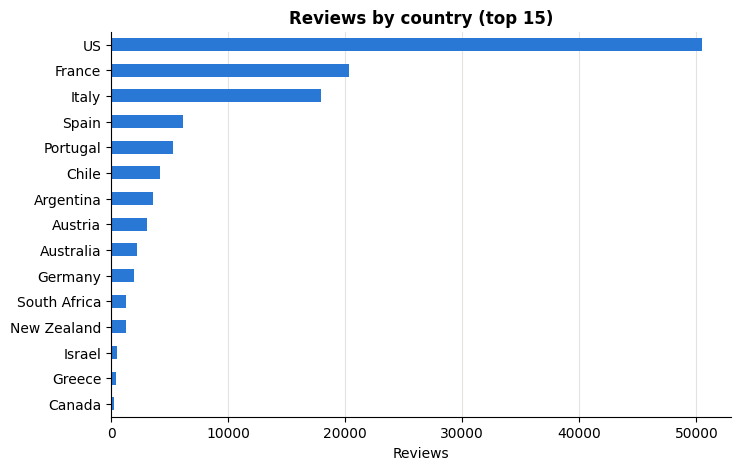

In [27]:
top_countries = df["country"].value_counts().head(15)
ax = top_countries.sort_values().plot.barh(color=BLUE, figsize=(8, 5))
ax.set(title="Reviews by country (top 15)", xlabel="Reviews", ylabel="")
ax.grid(axis="y", visible=False)

In [28]:
by_country = df.groupby("country_group").agg(reviews=("points", "size"), mean_points=("points", "mean"),
                                            median_price=("price", "median"))
by_country.sort_values("mean_points", ascending=False).round(2)

,reviews,mean_points,median_price
country_group,,,
England,63,91.75,50.0
Austria,3032,90.13,25.0
Germany,1992,89.90,27.0
Canada,226,89.31,30.0
Hungary,129,89.29,25.0
France,20349,88.87,25.0
Italy,17902,88.58,28.0
Australia,2196,88.56,21.0
US,50440,88.56,30.0


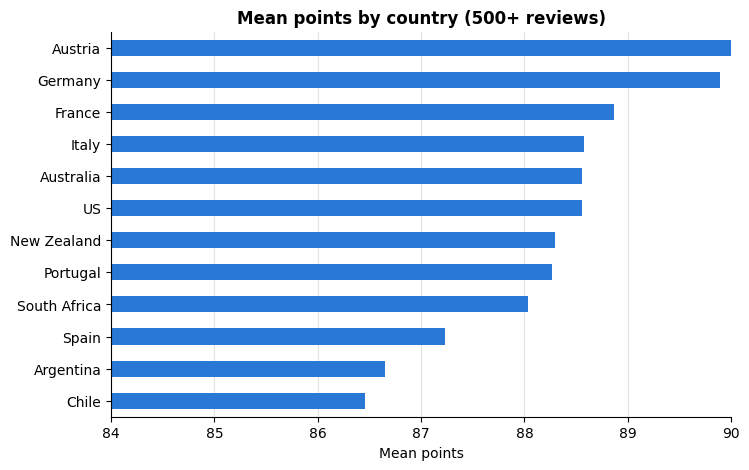

In [29]:
big = by_country[by_country["reviews"] >= 500].sort_values("mean_points")
ax = big["mean_points"].plot.barh(color=BLUE, figsize=(8, 5))
ax.set(title="Mean points by country (500+ reviews)", xlabel="Mean points", ylabel="", xlim=(84, 90))
ax.grid(axis="y", visible=False)

## Varieties

In [30]:
df["variety"].nunique()

707

In [31]:
top_varieties = df["variety"].value_counts().head(15).index
by_variety = (df[df["variety"].isin(top_varieties)]
              .groupby("variety").agg(reviews=("points", "size"), mean_points=("points", "mean"),
                                      median_price=("price", "median"))
              .sort_values("reviews", ascending=False))
by_variety.round(2)

,reviews,mean_points,median_price
variety,,,
Pinot Noir,12276,89.43,42.0
Chardonnay,10865,88.32,26.0
Cabernet Sauvignon,8833,88.62,38.0
Red Blend,8237,88.37,28.0
Bordeaux-style Red Blend,6467,89.13,30.0
Riesling,4773,89.48,22.0
Sauvignon Blanc,4574,87.38,18.0
Syrah,3824,89.31,35.0
Rosé,3220,86.77,16.0


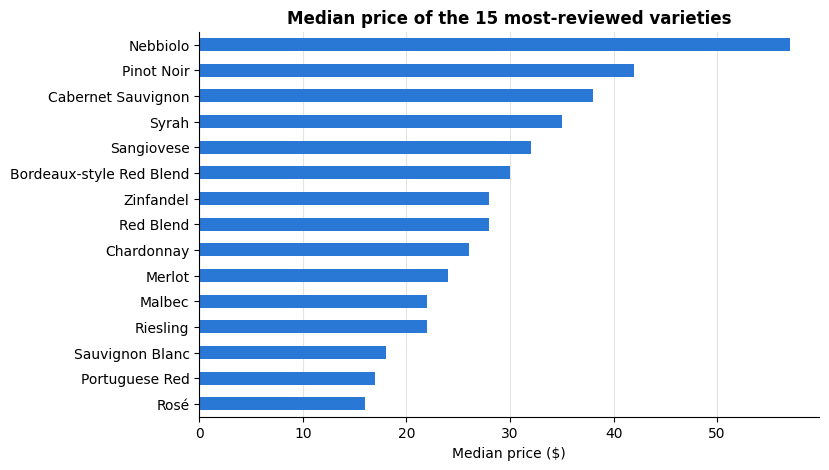

In [32]:
ax = by_variety["median_price"].sort_values().plot.barh(color=BLUE, figsize=(8, 5))
ax.set(title="Median price of the 15 most-reviewed varieties", xlabel="Median price ($)", ylabel="")
ax.grid(axis="y", visible=False)

## Tasters

In [33]:
by_taster = df.groupby("taster_name")["points"].agg(["size", "mean", "std"]).sort_values("size", ascending=False)
by_taster.round(2)

,size,mean,std
taster_name,,,
Roger Voss,23556,88.73,3.08
Michael Schachner,14044,86.86,3.07
Kerin O’Keefe,9661,88.90,2.53
Paul Gregutt,8867,89.09,2.85
Virginie Boone,8706,89.22,3.06
Matt Kettmann,5728,90.06,2.60
Joe Czerwinski,4763,88.53,2.90
Sean P. Sullivan,4459,88.76,2.51
Anna Lee C. Iijima,4017,88.42,2.61


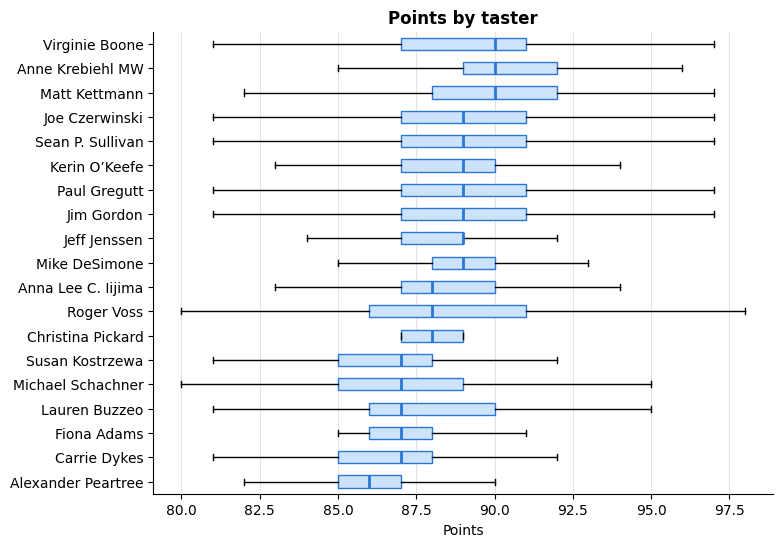

In [34]:
order = df.groupby("taster_name")["points"].median().sort_values().index
fig, ax = plt.subplots(figsize=(8, 6))
ax.boxplot([df.loc[df["taster_name"] == t, "points"] for t in order], vert=False, tick_labels=order,
           showfliers=False, patch_artist=True, boxprops={"facecolor": "#cde2fb", "edgecolor": BLUE},
           medianprops={"color": BLUE, "linewidth": 2})
ax.set(title="Points by taster", xlabel="Points")
ax.grid(axis="y", visible=False)

## Vintage

In [35]:
df["vintage"].describe()

count       115633.0
mean     2010.587064
std           3.6846
min           1934.0
25%           2009.0
50%           2011.0
75%           2013.0
max           2017.0
Name: vintage, dtype: Float64

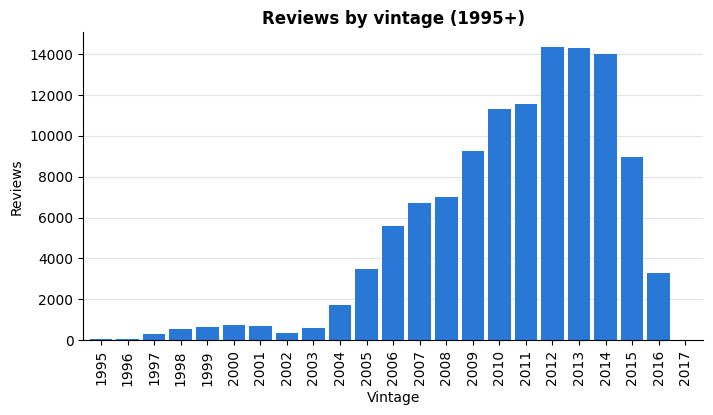

In [36]:
recent = df[df["vintage"] >= 1995]
ax = recent["vintage"].value_counts().sort_index().plot.bar(color=BLUE, width=0.85)
ax.set(title="Reviews by vintage (1995+)", xlabel="Vintage", ylabel="Reviews")
ax.grid(axis="x", visible=False)

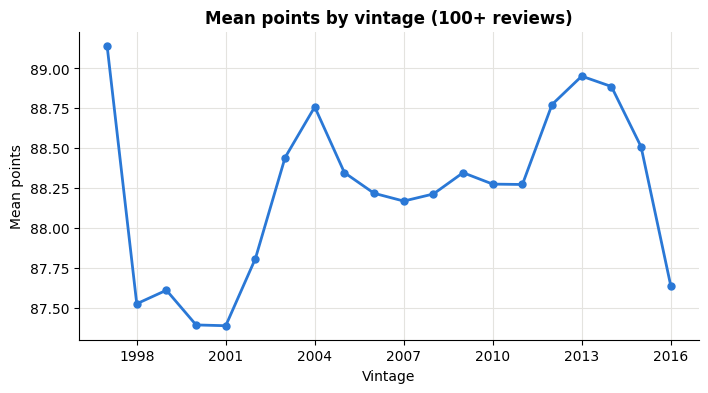

In [37]:
by_vintage = recent.groupby("vintage").agg(reviews=("points", "size"), mean_points=("points", "mean"))
by_vintage = by_vintage[by_vintage["reviews"] >= 100]
ax = by_vintage["mean_points"].plot(color=BLUE, linewidth=2, marker="o", markersize=5)
ax.set(title="Mean points by vintage (100+ reviews)", xlabel="Vintage", ylabel="Mean points")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))

## Description length

In [38]:
df["description_words"] = df["description"].str.split().str.len()
df["description_words"].describe()

count    119922.000000
mean         40.420206
std          11.205021
min           3.000000
25%          33.000000
50%          40.000000
75%          47.000000
max         135.000000
Name: description_words, dtype: float64

In [39]:
df[["description_words", "points"]].corr(method="spearman")

,description_words,points
description_words,1.000000,0.512114
points,0.512114,1.000000


[Text(0.5, 1.0, 'Median description length by points'),
 Text(0.5, 0, 'Points'),
 Text(0, 0.5, 'Words')]

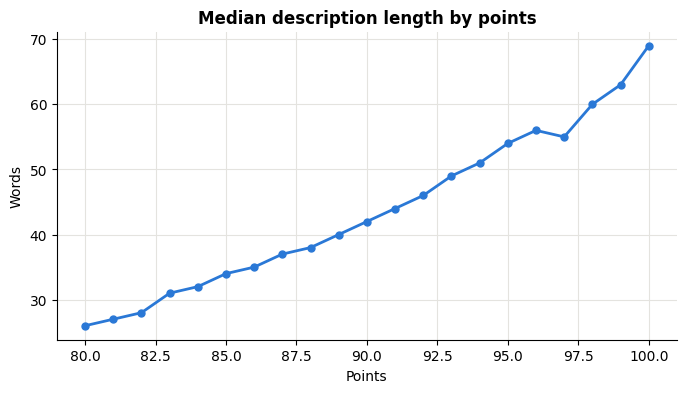

In [40]:
ax = df.groupby("points")["description_words"].median().plot(color=BLUE, linewidth=2, marker="o", markersize=5)
ax.set(title="Median description length by points", xlabel="Points", ylabel="Words")

## Best value

In [41]:
value = priced[priced["points"] >= 90].assign(points_per_dollar=lambda d: d["points"] / d["price"])
value.nlargest(10, "points_per_dollar")[["title", "variety", "country", "points", "price"]]

,title,variety,country,points,price
33935,Herdade dos Machados 2012 Toutalga Red (Alente...,Portuguese Red,Portugal,91,7.0
25746,Snoqualmie 2006 Winemaker's Select Riesling (C...,Riesling,US,91,8.0
5120,Esser Cellars 2001 Chardonnay (California),Chardonnay,US,90,8.0
67502,Aveleda 2013 Quinta da Aveleda Estate Bottled ...,Portuguese White,Portugal,90,8.0
72189,Rothbury Estate 2001 Chardonnay (South Eastern...,Chardonnay,Australia,90,8.0
10340,Chateau Ste. Michelle 2011 Riesling (Columbia ...,Riesling,US,91,9.0
42791,Chateau Ste. Michelle 2010 Dry Riesling (Colum...,Riesling,US,91,9.0
55033,Barnard Griffin 2012 Fumé Blanc Sauvignon Blan...,Sauvignon Blanc,US,91,9.0
7646,Mano A Mano 2011 Tempranillo (Vino de la Tierr...,Tempranillo,Spain,90,9.0
9690,Aveleda 2014 Quinta da Aveleda Estate Bottled ...,Portuguese White,Portugal,90,9.0
